In [1]:
import config.const
from src.tools.load_model import *

tokenizer, model , bert_tokenizer, bert_model = load_model(with_bert=True)

system check:
Python path: /usr/local/bin/python3.12
Torch version: 2.14.1+cu130
GPU: NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.14.1+cu130
CUDA: 13.0
CUDA available: True
Capability: (12, 0)
this is include the following functions torch , torch.nn.functional as F, transformers.AutoTokenizer, transformers.AutoModelForCausalLM


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [2]:
import sys
from pathlib import Path

import pandas as pd

# make analysis/ (the Qwen7B notebooks' code) importable
from config.const import PROJECT_ROOT
QWEN7B_DIR = PROJECT_ROOT / "src" / "note_books" / "Qwen7B"
if str(QWEN7B_DIR) not in sys.path:
    sys.path.insert(0, str(QWEN7B_DIR))

import analysis
from analysis.cluster import cluster, score, tree, tree_in_two
from analysis.signals import curves_of, dataset_names, kinds_of, load_tables, signal_by_key
from config.qwen_config import (BURST_DIR, BURST_TOKENS_DIR, BURST_WORDS_DIR, MANUAL_DIR, MANUAL_TOKENS_DIR,
                                MANUAL_WORDS_DIR, MODEL_NAME)

SIGNAL_KEYS = ["glove_top5", "lca_likely_top3_10pct", "lca_likely_top3_5pct", "lca_top5", "surprisal_per_word"]
SIGNALS = [signal_by_key(key) for key in SIGNAL_KEYS]   # the Signal objects (curves_of needs these, not the keys)
INCLUDE_REAL_TEXTS = True   # True: also cluster the 25 real texts from results/run together with these

# manual hallucinations: each original (original/*.txt) and its edited copy (*_manual.txt)
manual_names = []
for path in sorted((MANUAL_DIR / "original").glob("*.txt")):
    manual_names.append(path.stem)
    manual_names.append(f"{path.stem}_manual")

# bursts: each clean text and its copy with a hot burst (from bursts.csv)
bursts = pd.read_csv(BURST_DIR / "bursts.csv")
burst_names = list(bursts["clean original"]) + list(bursts["text"])

word_tables, token_tables = load_tables(manual_names, MODEL_NAME, MANUAL_WORDS_DIR, MANUAL_TOKENS_DIR)
burst_words, burst_tokens = load_tables(burst_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
word_tables.update(burst_words)
token_tables.update(burst_tokens)
names = manual_names + burst_names
source = {name: "manual" for name in manual_names} | {name: "burst" for name in burst_names}

if INCLUDE_REAL_TEXTS:
    real_names = dataset_names()
    real_words, real_tokens = load_tables(real_names, MODEL_NAME)
    word_tables.update(real_words)
    token_tables.update(real_tokens)
    names = names + real_names
    source.update({name: "real" for name in real_names})

kinds = kinds_of(names)
hallucinated = [name.endswith("_manual") or "_burst_" in name for name in names]
print(f"{len(names)} texts: {(kinds == 'factual').sum()} factual, {(kinds == 'creative').sum()} creative, "
      f"{sum(hallucinated)} hallucinated")

result_rows = []
label_rows = {}
clusterings = {}          # signal key -> (labels, centres, DTW distance table), for the graphs
for signal in SIGNALS:
    curves = curves_of(signal, names, word_tables, token_tables)
    labels, centres, distances = cluster(curves)
    row = {"signal": signal.key, "name": signal.name}
    row.update(score(names, kinds, labels))
    row["tree cut in two: correct"] = score(names, kinds, tree_in_two(tree(distances)))["correct"]
    row["centre texts"] = f"{names[centres[0]]}, {names[centres[1]]}"
    result_rows.append(row)
    label_rows[signal.key] = labels
    clusterings[signal.key] = (labels, centres, distances)

results = pd.DataFrame(result_rows).sort_values("correct", ascending=False)
pd.set_option("display.max_colwidth", 120)
results[["name", "correct", "texts", "factual correct", "creative correct", "tree cut in two: correct",
         "centre texts", "wrong cluster"]]

49 texts: 24 factual, 25 creative, 12 hallucinated


,name,correct,texts,factual correct,creative correct,tree cut in two: correct,centre texts,wrong cluster
3,"LCA height, top 5 guesses",38,49,18,20,29,"factual_burst_paris, creative_hp5","factual_wiki_saturn_manual, factual_clean_apollo, factual_clean_vaccines, creative_clean_fairy, factual_burst_apollo..."
1,"LCA height, likely guesses, at most 3 (10%)",31,49,19,12,30,"factual_burst_paris, creative_gut_oz","creative_gut_peter_pan, creative_gut_peter_pan_manual, creative_gut_treasure_island, creative_gut_treasure_island_ma..."
0,"GloVe distance, top 5 guesses",27,49,24,3,38,"creative_gut_wind_willows_manual, factual_burst_apollo","creative_gut_peter_pan, creative_gut_peter_pan_manual, creative_gut_treasure_island, creative_gut_treasure_island_ma..."
4,surprisal per word,26,49,18,8,25,"creative_clean_magic, factual_gut_origin_species","creative_gut_peter_pan, creative_gut_peter_pan_manual, creative_gut_treasure_island, creative_gut_treasure_island_ma..."
2,"LCA height, likely guesses, at most 3 (5%)",25,49,0,25,27,"creative_gut_peter_pan_manual, creative_gut_oz","factual_wiki_honey_bee, factual_wiki_honey_bee_manual, factual_wiki_moon, factual_wiki_moon_manual, factual_wiki_sat..."


In [3]:
import numpy as np

# which cluster each text landed in, for the chosen signals (one column per signal).
# A cluster has no name of its own (k-medoids labels it 0 or 1), so each is named after the kind most of its texts have.
CHOSEN_SIGNALS = ["glove_top5", "lca_likely_top3_10pct", "lca_likely_top3_5pct","lca_top5", "surprisal_per_word"]   # GloVe top 5, LCA likely (10%) top 3, surprisal


def cluster_names(labels, kinds):
    """'factual' / 'creative' per text: the kind most texts in its cluster have."""
    named = np.empty(len(labels), dtype=object)
    for cluster_label in set(labels):
        members = labels == cluster_label
        named[members] = pd.Series(kinds[members]).mode()[0]
    return named


assignments = pd.DataFrame({"text": names, "source": [source[n] for n in names], "kind": kinds,
                            "hallucinated": hallucinated})
for key in CHOSEN_SIGNALS:
    assignments[key] = cluster_names(np.asarray(label_rows[key]), kinds)
    assignments[f"{key} right"] = assignments[key] == assignments["kind"]
assignments

,text,source,kind,hallucinated,glove_top5,glove_top5 right,lca_likely_top3_10pct,lca_likely_top3_10pct right,lca_likely_top3_5pct,lca_likely_top3_5pct right,lca_top5,lca_top5 right,surprisal_per_word,surprisal_per_word right
0,creative_gut_peter_pan,manual,creative,False,factual,False,factual,False,creative,True,creative,True,factual,False
1,creative_gut_peter_pan_manual,manual,creative,True,factual,False,factual,False,creative,True,creative,True,factual,False
2,creative_gut_treasure_island,manual,creative,False,factual,False,factual,False,creative,True,creative,True,factual,False
3,creative_gut_treasure_island_manual,manual,creative,True,factual,False,factual,False,creative,True,creative,True,factual,False
4,creative_gut_wind_willows,manual,creative,False,creative,True,factual,False,creative,True,creative,True,factual,False
5,creative_gut_wind_willows_manual,manual,creative,True,creative,True,factual,False,creative,True,creative,True,factual,False
6,factual_wiki_honey_bee,manual,factual,False,factual,True,factual,True,creative,False,factual,True,factual,True
7,factual_wiki_honey_bee_manual,manual,factual,True,factual,True,factual,True,creative,False,factual,True,factual,True
8,factual_wiki_moon,manual,factual,False,factual,True,factual,True,creative,False,factual,True,factual,True
9,factual_wiki_moon_manual,manual,factual,True,factual,True,factual,True,creative,False,factual,True,factual,True


/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


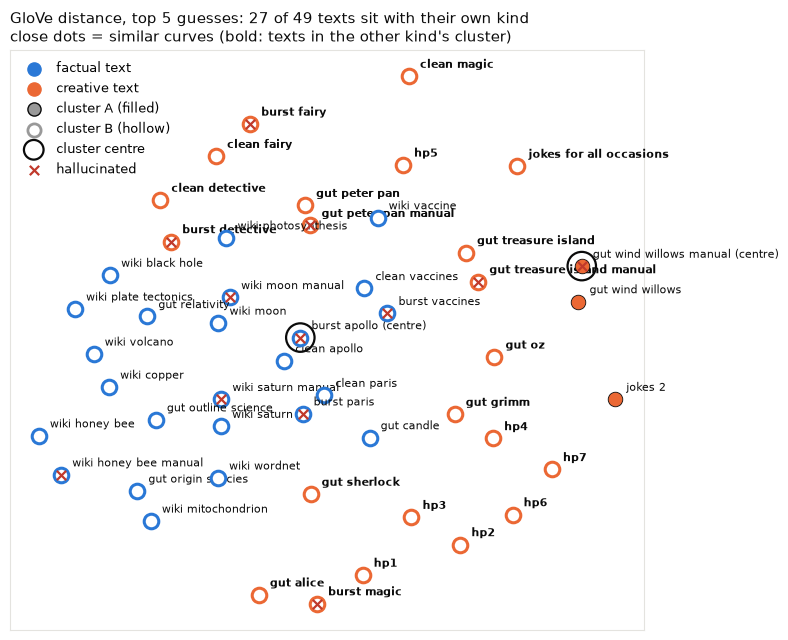

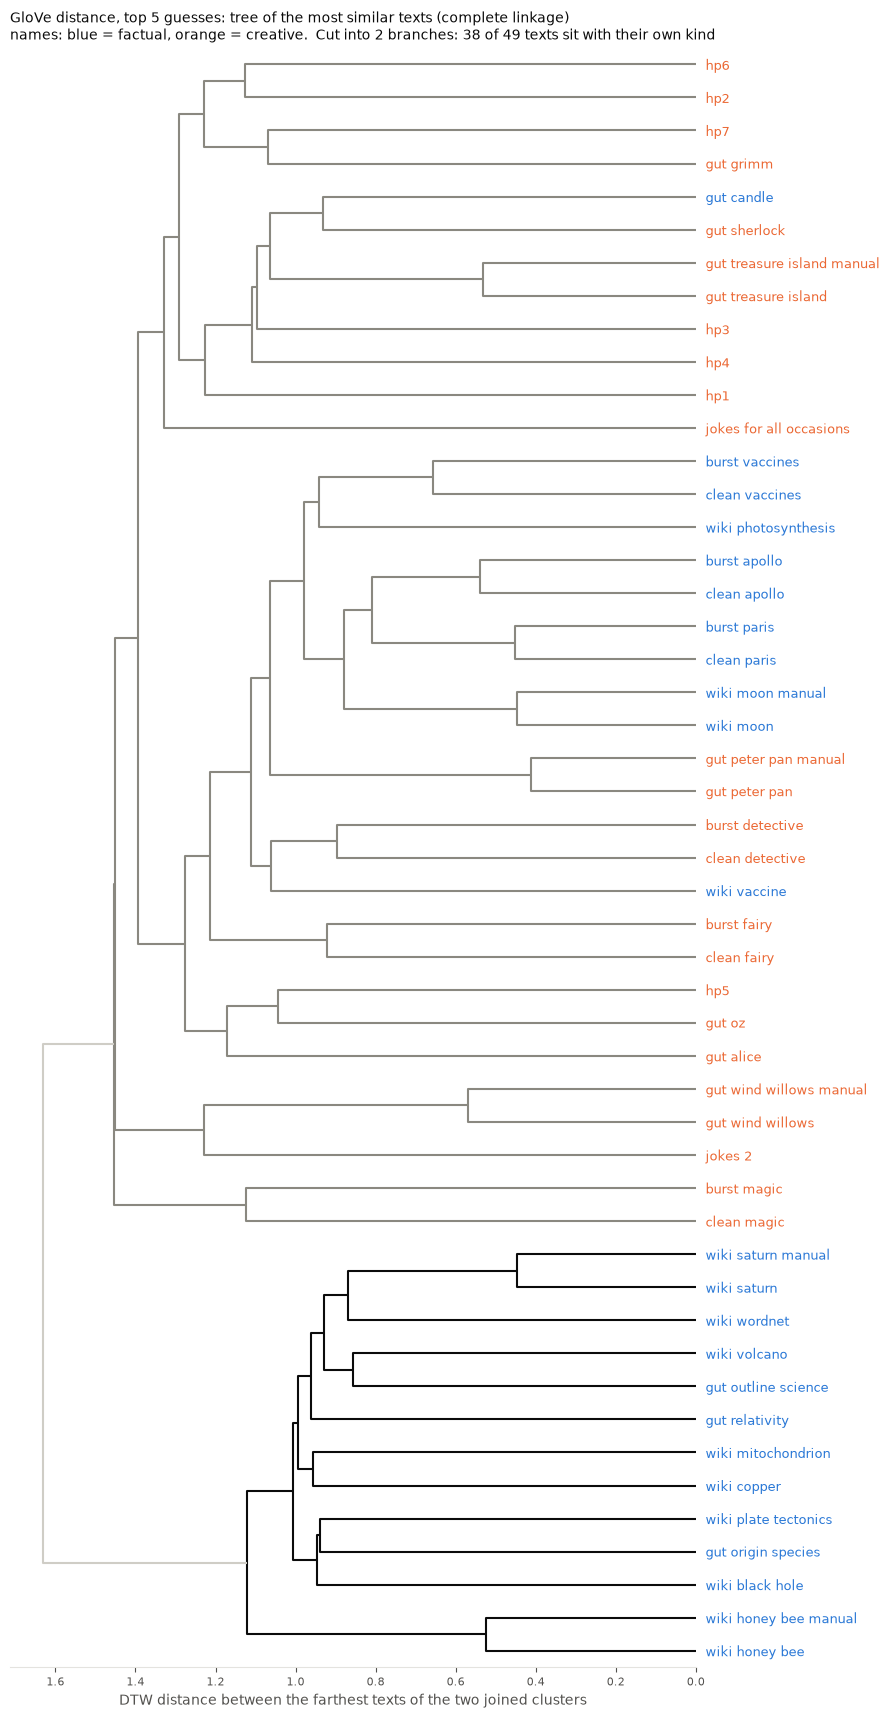

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


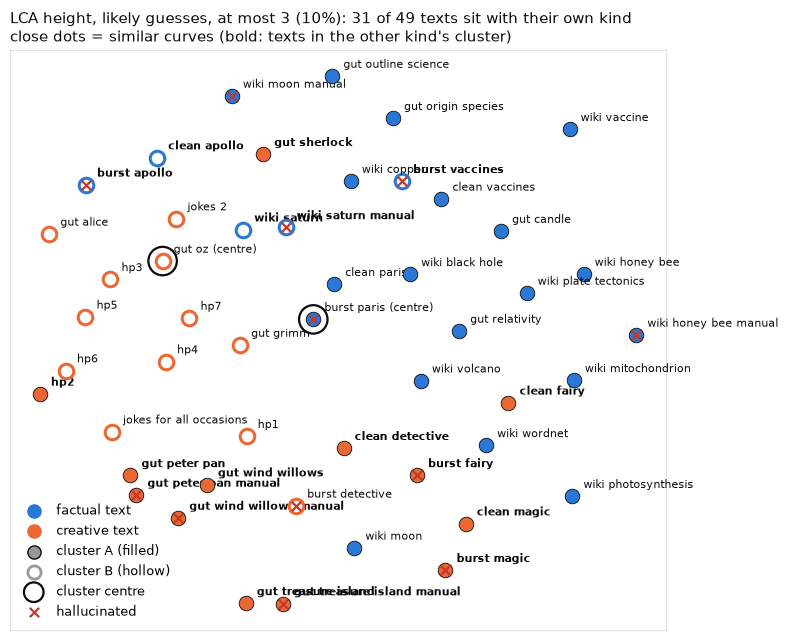

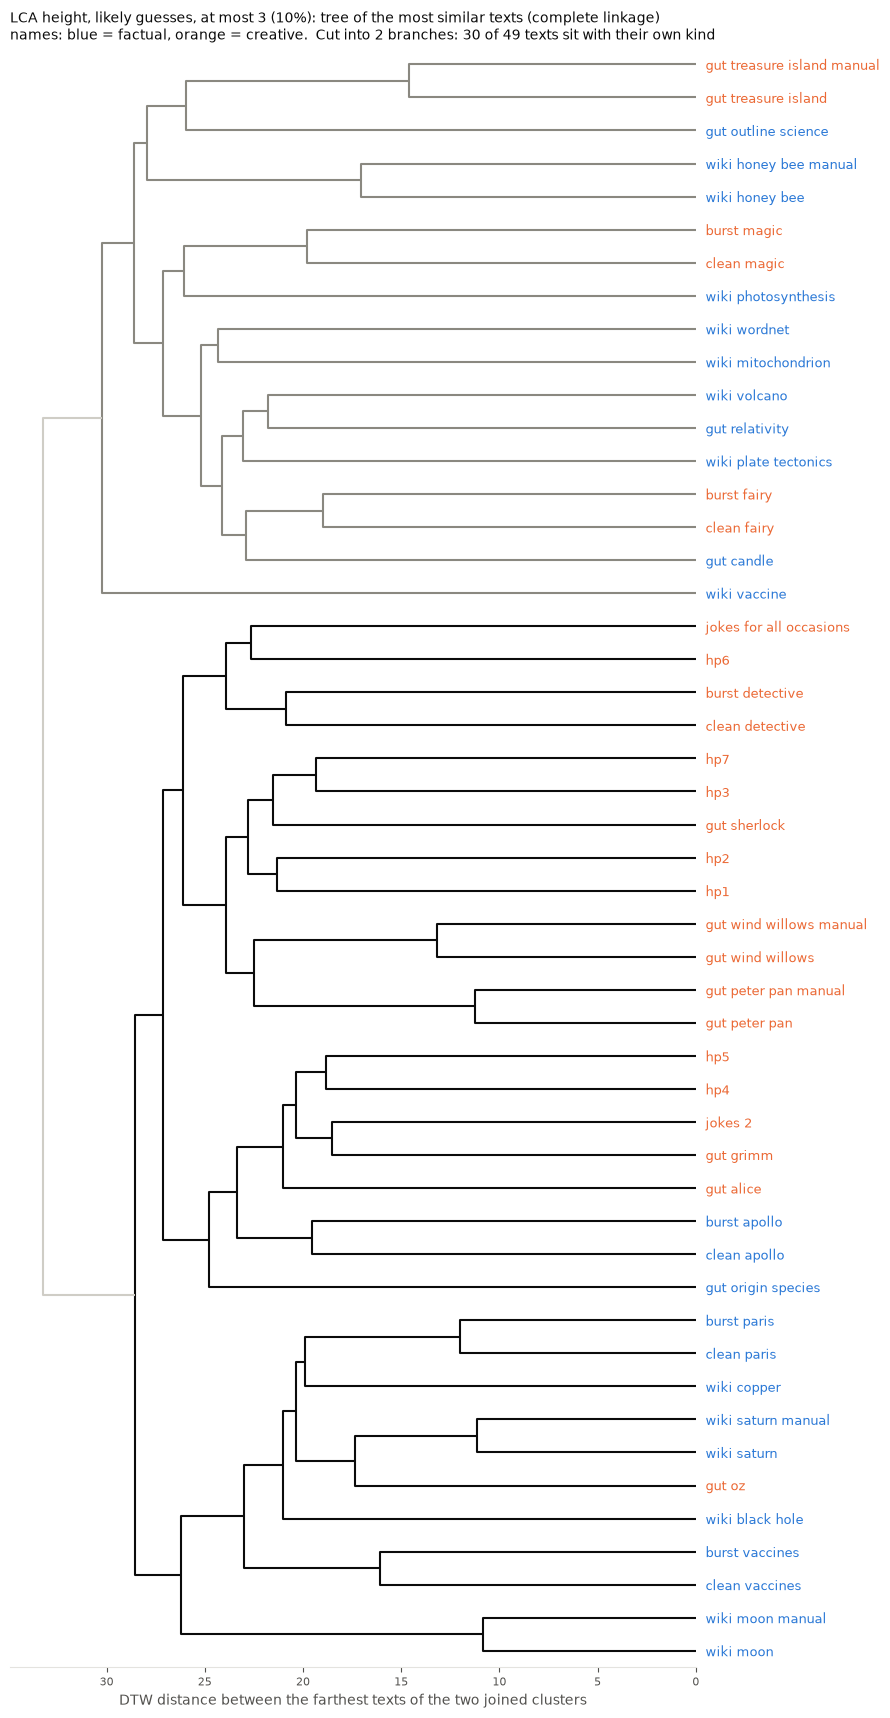

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


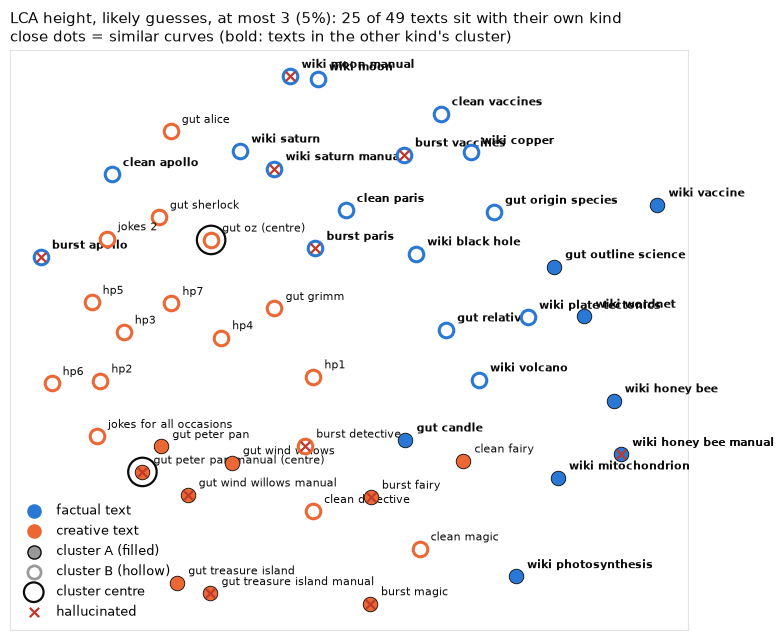

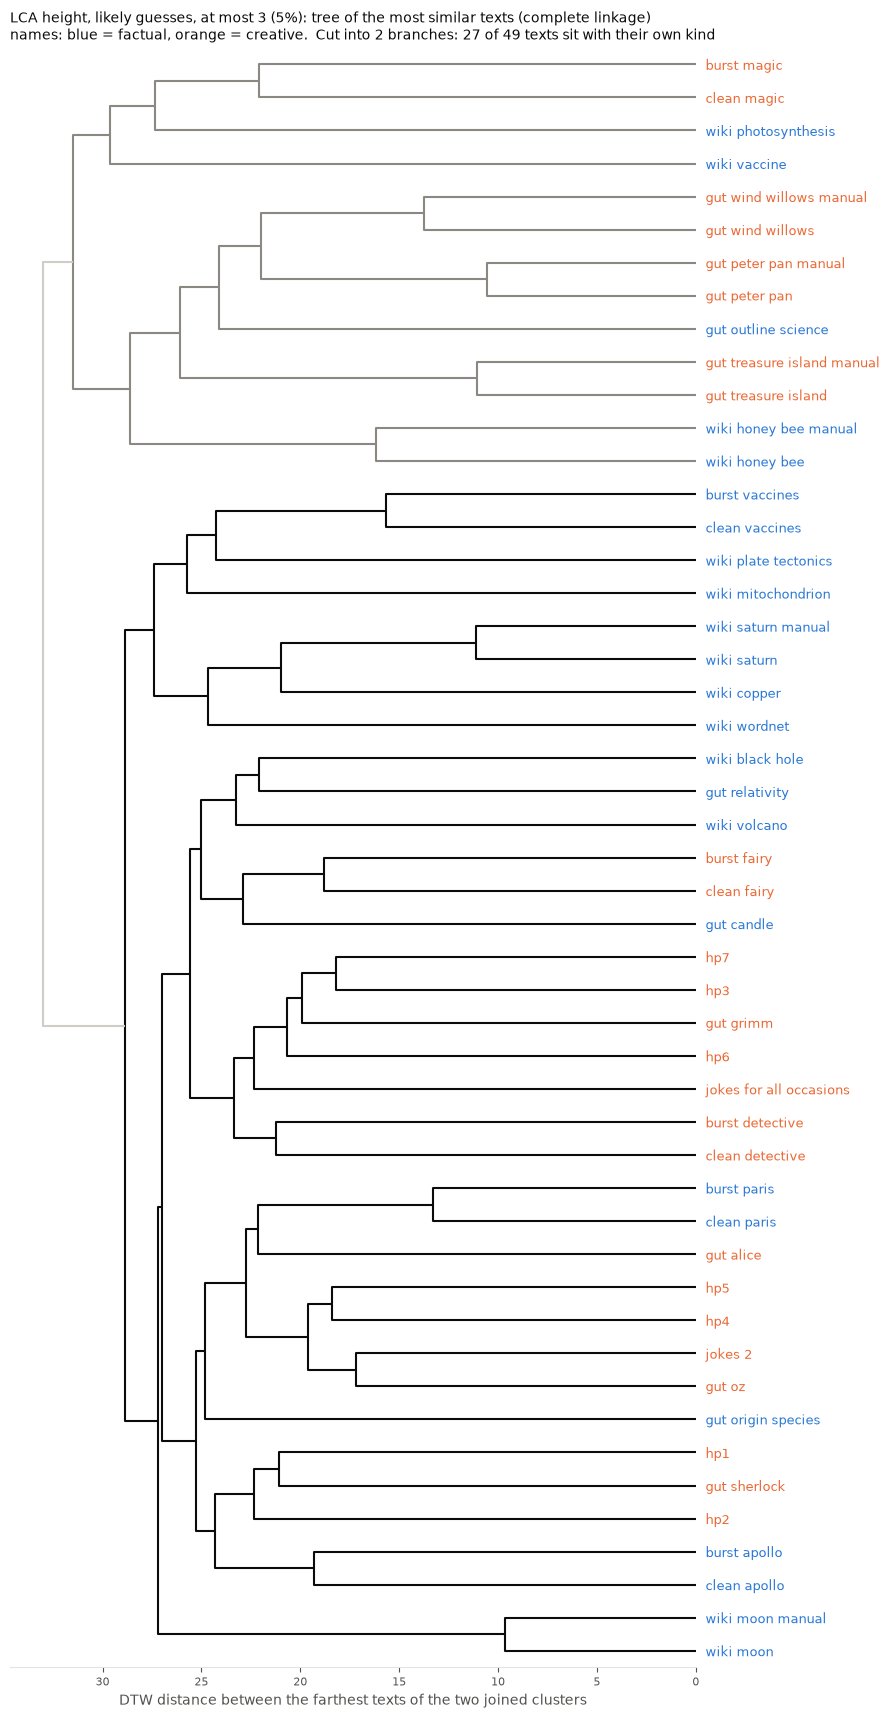

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


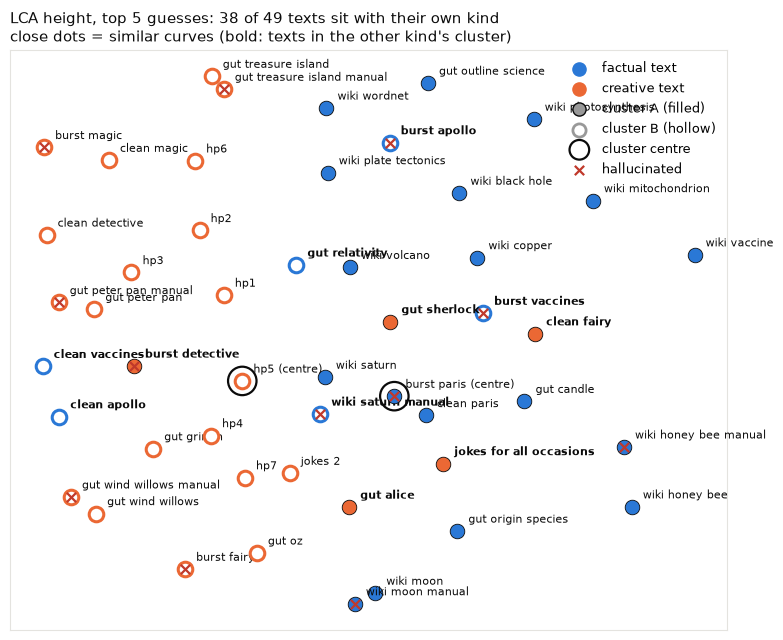

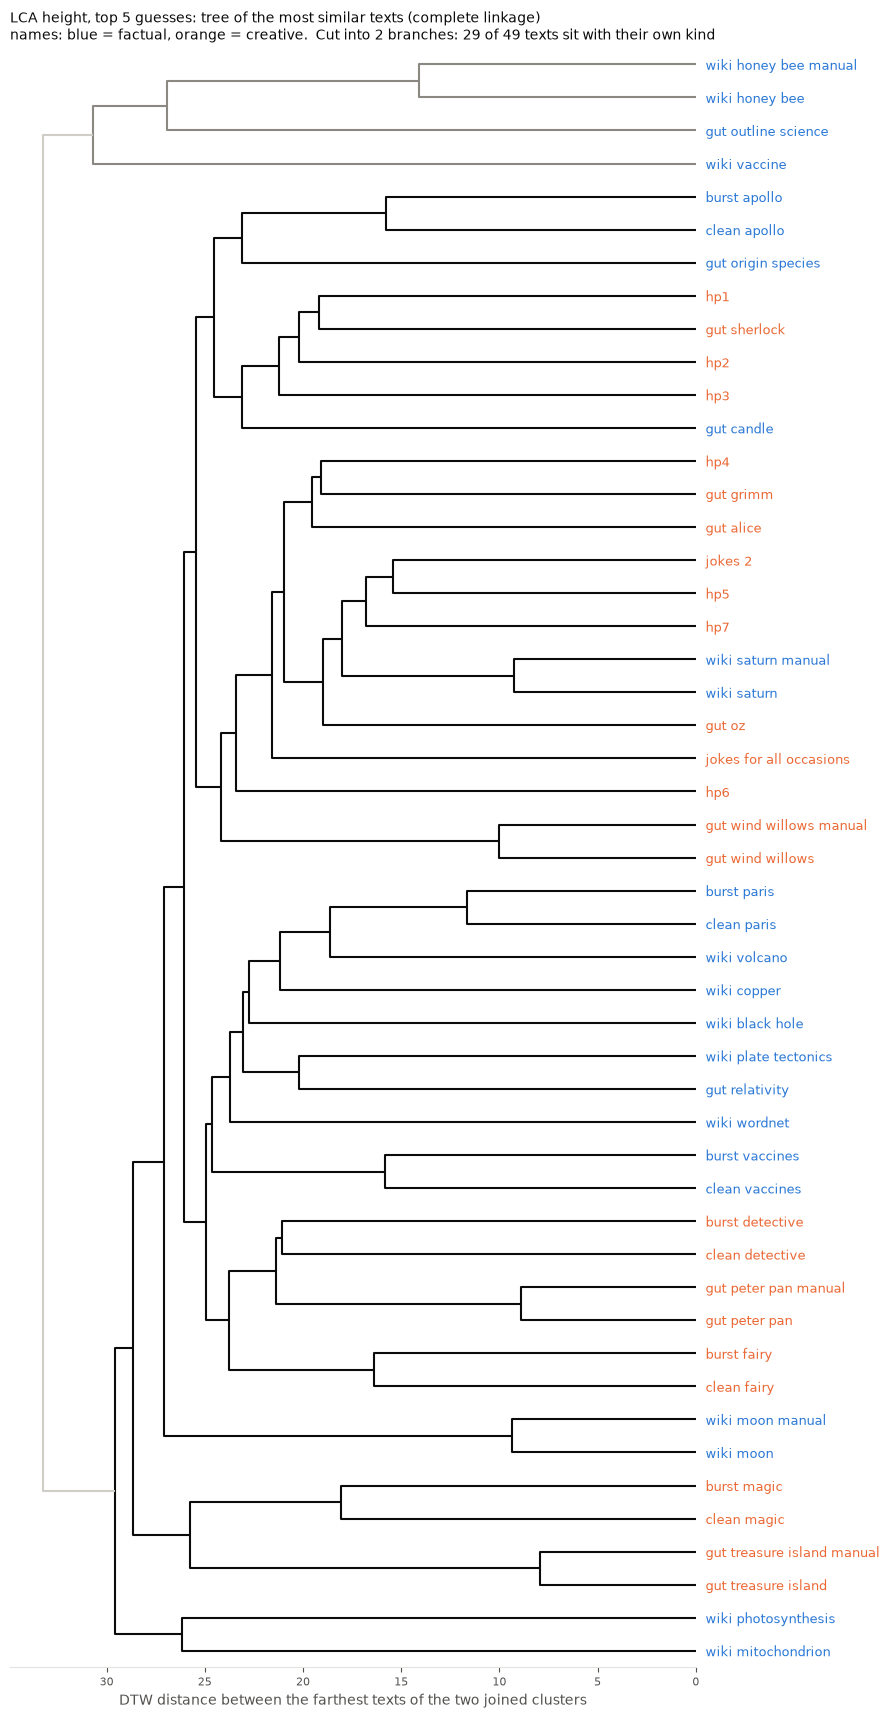

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


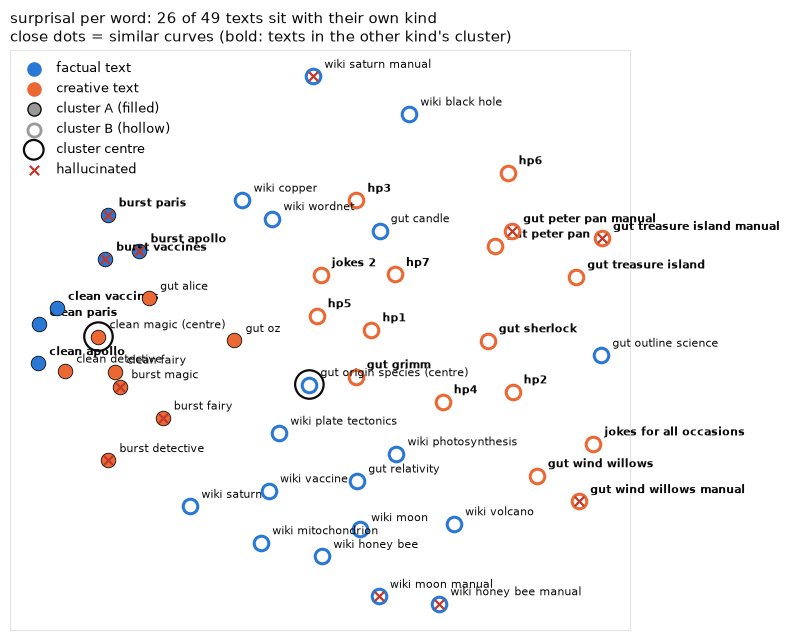

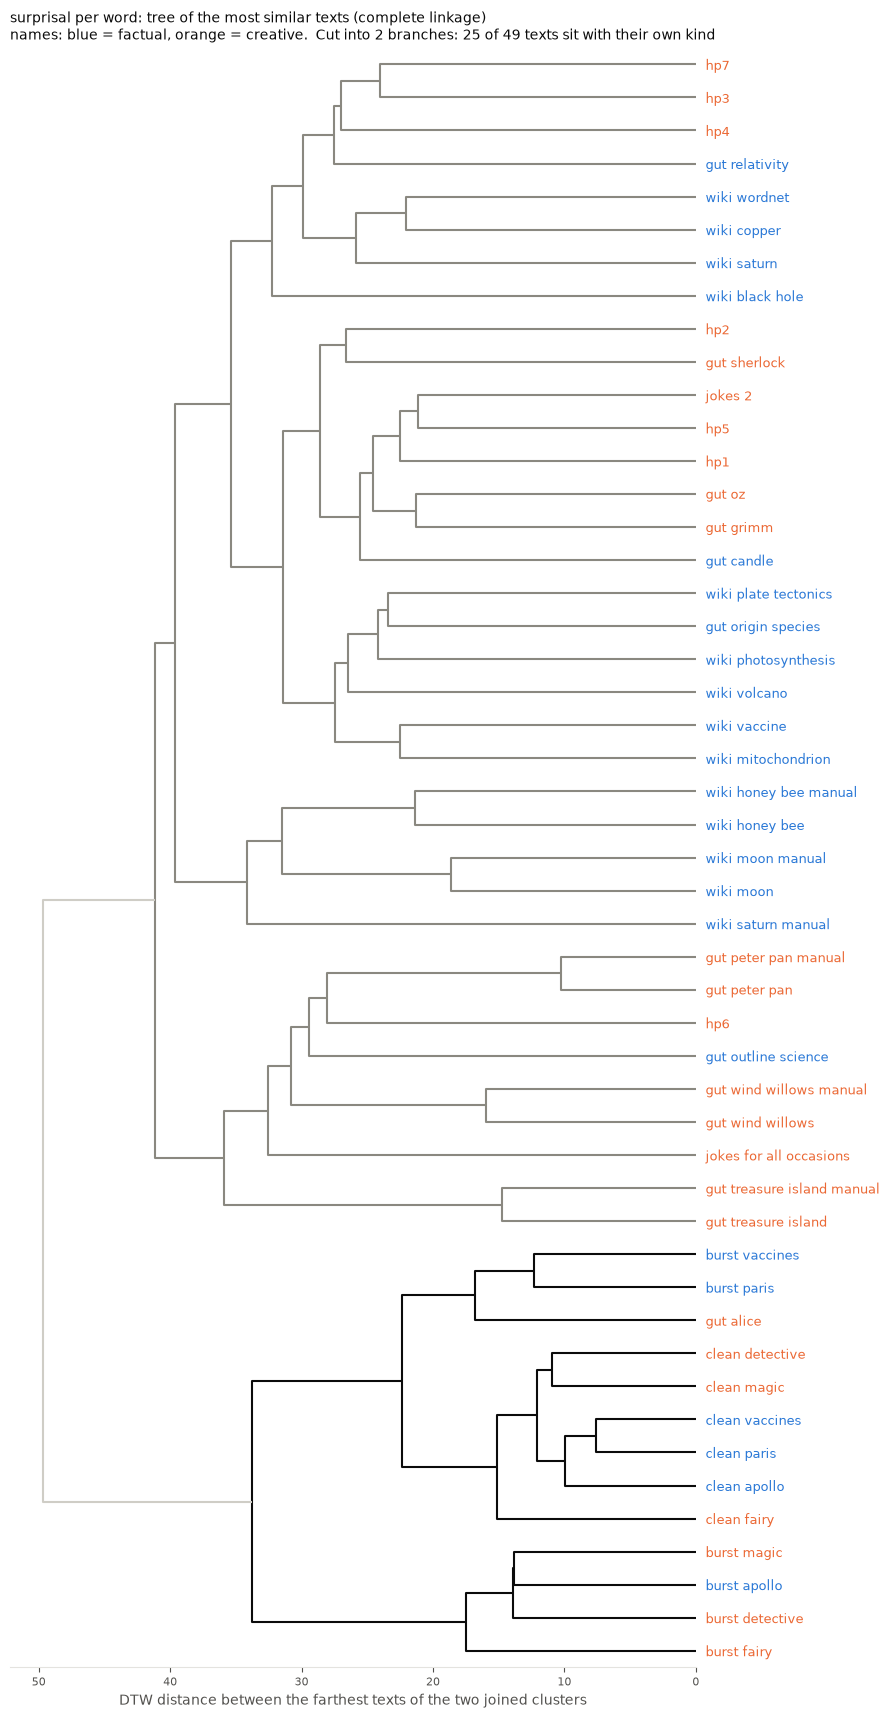

In [4]:
import matplotlib.pyplot as plt

from analysis.cluster import text_map
from analysis.figures import HALLUCINATION_COLOR, plot_dendrogram, plot_text_map

# one text map and one tree per chosen signal
#   map:  close dots = similar curves (DTW). Colour = real kind, filled / hollow = the two clusters,
#         black ring = cluster centre, bold name = in the other kind's cluster, red x = hallucinated text
#   tree: texts joined further right the less similar their curves are
for key in CHOSEN_SIGNALS:
    labels, centres, distances = clusterings[key]
    signal_name = signal_by_key(key).name

    coordinates = text_map(distances)
    fig = plot_text_map(signal_name, coordinates, names, kinds, labels, centres)
    ax = fig.axes[0]
    marked = np.asarray(hallucinated)
    ax.scatter(coordinates[marked, 0], coordinates[marked, 1], marker="x", s=45, color=HALLUCINATION_COLOR,
               linewidth=1.6, zorder=4, label="hallucinated")
    ax.legend(handles=ax.get_legend().legend_handles + [ax.collections[-1]], frameon=False, fontsize=9, loc="best")
    plt.show()

    correct_when_cut = score(names, kinds, tree_in_two(tree(distances)))["correct"]
    plot_dendrogram(signal_name, tree(distances), names, kinds, correct_when_cut)
    plt.show()

,signal,real: in own kind's cluster,real: leave-one-out 1-NN,new: 1-NN right,new: nearer centre right
0,"GloVe distance, top 5 guesses",23/25,20/25,13/24,14/24
1,"LCA height, likely guesses, at most 3 (10%)",23/25,20/25,10/24,8/24
2,"LCA height, likely guesses, at most 3 (5%)",20/25,21/25,11/24,8/24
3,"LCA height, top 5 guesses",16/25,17/25,8/24,12/24
4,surprisal per word,22/25,22/25,17/24,16/24


/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


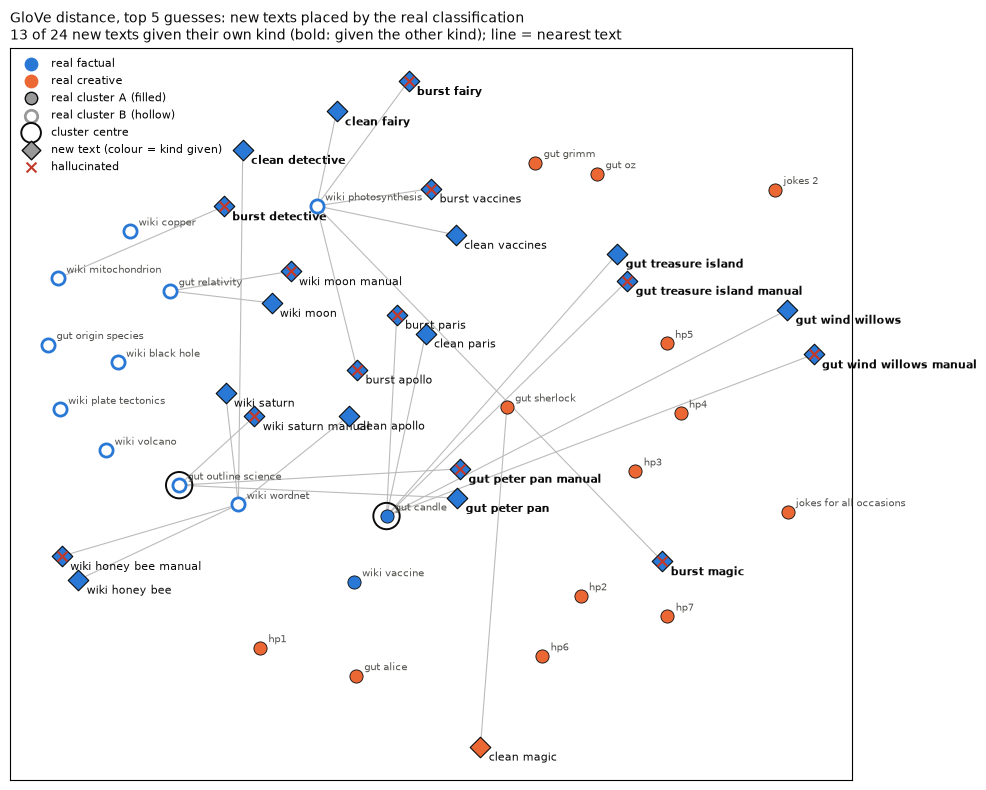

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


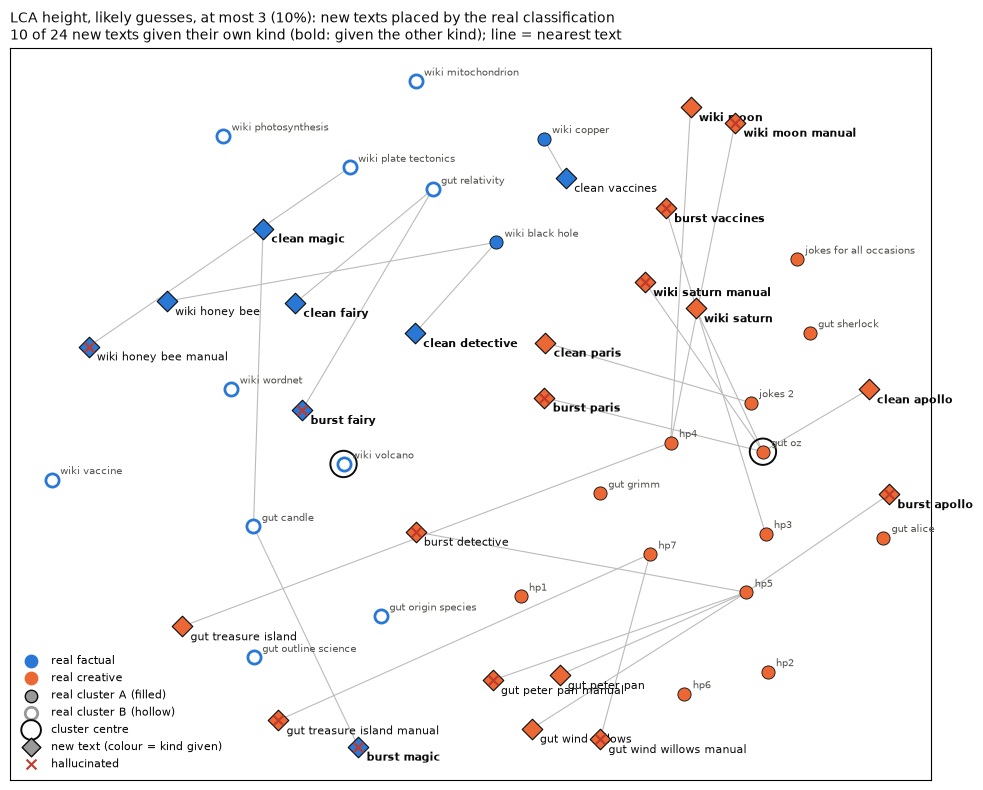

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


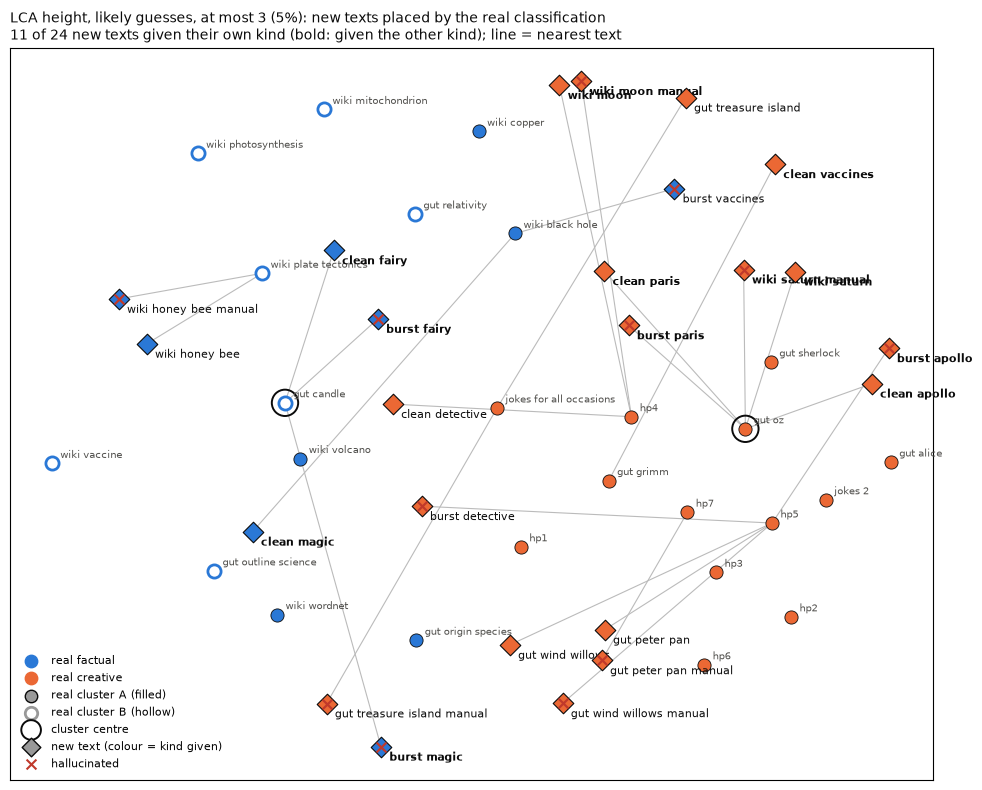

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


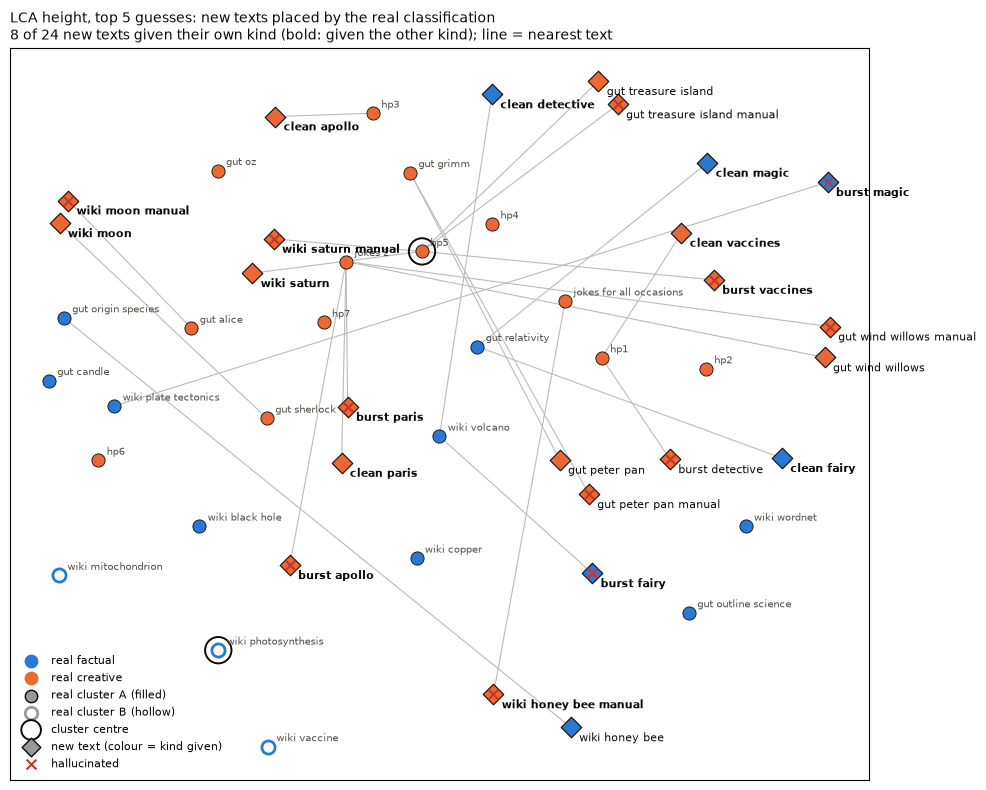

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


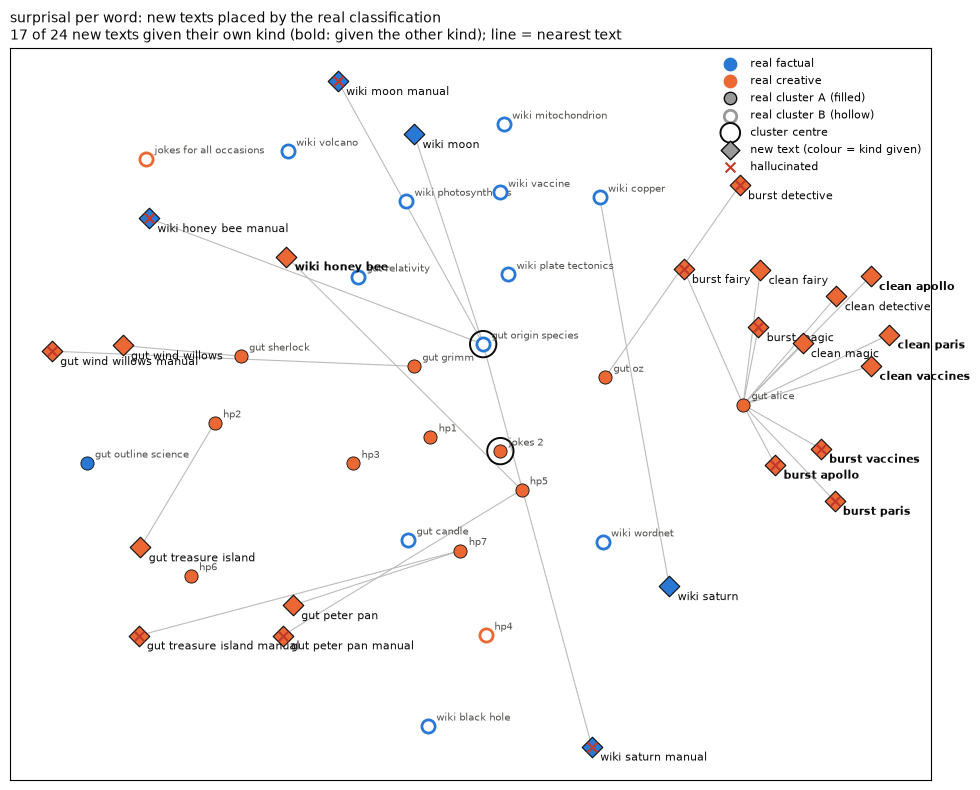

,signal,text,source,kind,hallucinated,1-NN kind,1-NN right,nearest text,nearer centre,centre right
0,"GloVe distance, top 5 guesses",creative_gut_peter_pan,manual,creative,False,factual,False,factual_gut_outline_science,factual,False
1,"GloVe distance, top 5 guesses",creative_gut_peter_pan_manual,manual,creative,True,factual,False,factual_gut_outline_science,factual,False
2,"GloVe distance, top 5 guesses",creative_gut_treasure_island,manual,creative,False,factual,False,factual_gut_candle,creative,True
3,"GloVe distance, top 5 guesses",creative_gut_treasure_island_manual,manual,creative,True,factual,False,factual_gut_candle,creative,True
4,"GloVe distance, top 5 guesses",creative_gut_wind_willows,manual,creative,False,factual,False,factual_gut_candle,creative,True
...,...,...,...,...,...,...,...,...,...,...
115,surprisal per word,factual_burst_apollo,burst,factual,True,creative,False,creative_gut_alice,creative,False
116,surprisal per word,factual_burst_vaccines,burst,factual,True,creative,False,creative_gut_alice,creative,False
117,surprisal per word,creative_burst_magic,burst,creative,True,creative,True,creative_gut_alice,factual,False
118,surprisal per word,creative_burst_fairy,burst,creative,True,creative,True,creative_gut_alice,creative,True


In [5]:
# Classify new texts against the REAL texts' classification.
#   1. the 25 real (human) texts are clustered first (k-medoids on DTW, as in 02_results); each cluster is named
#      after the kind most of its texts have. How well the real texts classify each other is checked with
#      leave-one-out 1-NN (each real text labelled from the other 24).
#   2. every new text (the manual + burst texts from cell 1) is placed near that classification:
#        1-NN kind       the kind of the single real text whose curve is closest (DTW)
#        nearer centre   the real cluster whose centre text is closer
#   The classifier learns only from the real texts. LEARN_FROM_NEW = True also adds each new text, once
#   classified, to the references with the kind it was given, so later new texts are compared with it too.
from tslearn.metrics import cdist_dtw
from tslearn.utils import to_time_series_dataset

from analysis.classify import cluster_kinds, leave_one_out
from analysis.cluster import dtw_radius, in_right_cluster, k_medoids
from analysis.figures import INK, INK_SOFT, KIND_COLORS, short_name

LEARN_FROM_NEW = False

real_names = dataset_names()
real_kinds = list(kinds_of(real_names))
if not all(name in word_tables for name in real_names):
    real_words, real_tokens = load_tables(real_names, MODEL_NAME)
    word_tables.update(real_words)
    token_tables.update(real_tokens)
new_names = [name for name in names if source[name] != "real"]
new_kinds = list(kinds_of(new_names))
all_names = real_names + new_names
R = len(real_names)

summary_rows = []
new_rows = []
placements = {}          # signal key -> what the map below needs
for key in CHOSEN_SIGNALS:
    signal = signal_by_key(key)
    real_curves = curves_of(signal, real_names, word_tables, token_tables)
    new_curves = curves_of(signal, new_names, word_tables, token_tables)
    # one DTW table over real + new texts; the shift limit comes from the real texts only
    full = cdist_dtw(to_time_series_dataset(real_curves + new_curves), global_constraint="sakoe_chiba",
                     sakoe_chiba_radius=dtw_radius(real_curves))

    # 1. the real classification
    real_labels, real_centres = k_medoids(full[:R, :R])
    try:
        kind_of_cluster = cluster_kinds(real_labels, real_kinds)
    except ValueError:                      # both clusters mostly the same kind: the centres can't name a kind
        kind_of_cluster = None
    given, _nearest = leave_one_out(full[:R, :R], real_kinds)
    loo_right = sum(g == k for g, k in zip(given, real_kinds))
    clusters_right = int(in_right_cluster(np.asarray(real_kinds), real_labels).sum())

    # 2. the new texts, one at a time, against the references (real, plus earlier new ones if LEARN_FROM_NEW)
    reference_index = list(range(R))
    reference_kinds = list(real_kinds)
    given_new = []
    nearest_new = []
    for n, name in enumerate(new_names):
        row = full[R + n]
        position = int(np.argmin(row[reference_index]))
        closest = reference_index[position]
        nn_kind = reference_kinds[position]
        if kind_of_cluster is None:
            centre_kind = "?"
        elif row[real_centres[1]] < row[real_centres[0]]:
            centre_kind = kind_of_cluster[1]
        else:
            centre_kind = kind_of_cluster[0]
        new_rows.append({"signal": signal.name, "text": name, "source": source[name], "kind": new_kinds[n],
                         "hallucinated": hallucinated[names.index(name)],
                         "1-NN kind": nn_kind, "1-NN right": nn_kind == new_kinds[n],
                         "nearest text": all_names[closest],
                         "nearer centre": centre_kind, "centre right": centre_kind == new_kinds[n]})
        given_new.append(nn_kind)
        nearest_new.append(closest)
        if LEARN_FROM_NEW:
            reference_index.append(R + n)
            reference_kinds.append(nn_kind)

    new_table = pd.DataFrame(new_rows[-len(new_names):])
    summary_rows.append({"signal": signal.name,
                         "real: in own kind's cluster": f"{clusters_right}/{R}",
                         "real: leave-one-out 1-NN": f"{loo_right}/{R}",
                         "new: 1-NN right": f"{int(new_table['1-NN right'].sum())}/{len(new_names)}",
                         "new: nearer centre right": f"{int(new_table['centre right'].sum())}/{len(new_names)}"})
    placements[key] = (full, real_labels, real_centres, given_new, nearest_new)

new_results = pd.DataFrame(new_rows)
display(pd.DataFrame(summary_rows))

# map: the real texts (dots: colour = kind, filled / hollow = real cluster, ring = centre) and every new text
# (diamond, coloured by the kind 1-NN gave it, red x = hallucinated) with a thin line to its nearest text
for key in CHOSEN_SIGNALS:
    full, real_labels, real_centres, given_new, nearest_new = placements[key]
    coordinates = text_map(full)
    fig, ax = plt.subplots(figsize=(10, 8))
    for i in range(R):
        x, y = coordinates[i]
        color = KIND_COLORS[real_kinds[i]]
        if real_labels[i] == 0:
            ax.scatter(x, y, s=90, color=color, edgecolor=INK, linewidth=0.6, zorder=3)
        else:
            ax.scatter(x, y, s=90, facecolor="white", edgecolor=color, linewidth=2, zorder=3)
        if i in real_centres:
            ax.scatter(x, y, s=360, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=2)
        ax.annotate(short_name(real_names[i]), (x, y), xytext=(6, 4), textcoords="offset points", fontsize=7,
                    color=INK_SOFT)
    for n, name in enumerate(new_names):
        x, y = coordinates[R + n]
        nx, ny = coordinates[nearest_new[n]]
        ax.plot([x, nx], [y, ny], color="#bbbbbb", lw=0.8, zorder=1)
        ax.scatter(x, y, s=110, marker="D", color=KIND_COLORS[given_new[n]], edgecolor=INK, linewidth=0.8, zorder=4)
        if hallucinated[names.index(name)]:
            ax.scatter(x, y, s=50, marker="x", color=HALLUCINATION_COLOR, linewidth=1.6, zorder=5)
        weight = "normal" if given_new[n] == new_kinds[n] else "bold"
        ax.annotate(short_name(name), (x, y), xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK,
                    fontweight=weight)
    legend_items = [
        plt.scatter([], [], s=80, color=KIND_COLORS["factual"], label="real factual"),
        plt.scatter([], [], s=80, color=KIND_COLORS["creative"], label="real creative"),
        plt.scatter([], [], s=80, color="#999999", edgecolor=INK, label="real cluster A (filled)"),
        plt.scatter([], [], s=80, facecolor="white", edgecolor="#999999", linewidth=2, label="real cluster B (hollow)"),
        plt.scatter([], [], s=200, facecolor="none", edgecolor=INK, linewidth=1.4, label="cluster centre"),
        plt.scatter([], [], s=90, marker="D", color="#999999", edgecolor=INK, label="new text (colour = kind given)"),
        plt.scatter([], [], s=50, marker="x", color=HALLUCINATION_COLOR, label="hallucinated"),
    ]
    ax.legend(handles=legend_items, frameon=False, fontsize=8, loc="best")
    ax.set_xticks([])
    ax.set_yticks([])
    right = sum(g == k for g, k in zip(given_new, new_kinds))
    ax.set_title(f"{signal_by_key(key).name}: new texts placed by the real classification\n"
                 f"{right} of {len(new_names)} new texts given their own kind (bold: given the other kind); "
                 "line = nearest text", loc="left", fontsize=10, color=INK)
    fig.tight_layout()
    plt.show()

new_results